Total records: 29200
Date range: 2024-01-01 00:00:00 → 2025-12-30 00:00:00
Zones: 8
Waste types: ['plastic' 'organic' 'metal' 'glass' 'hazardous']


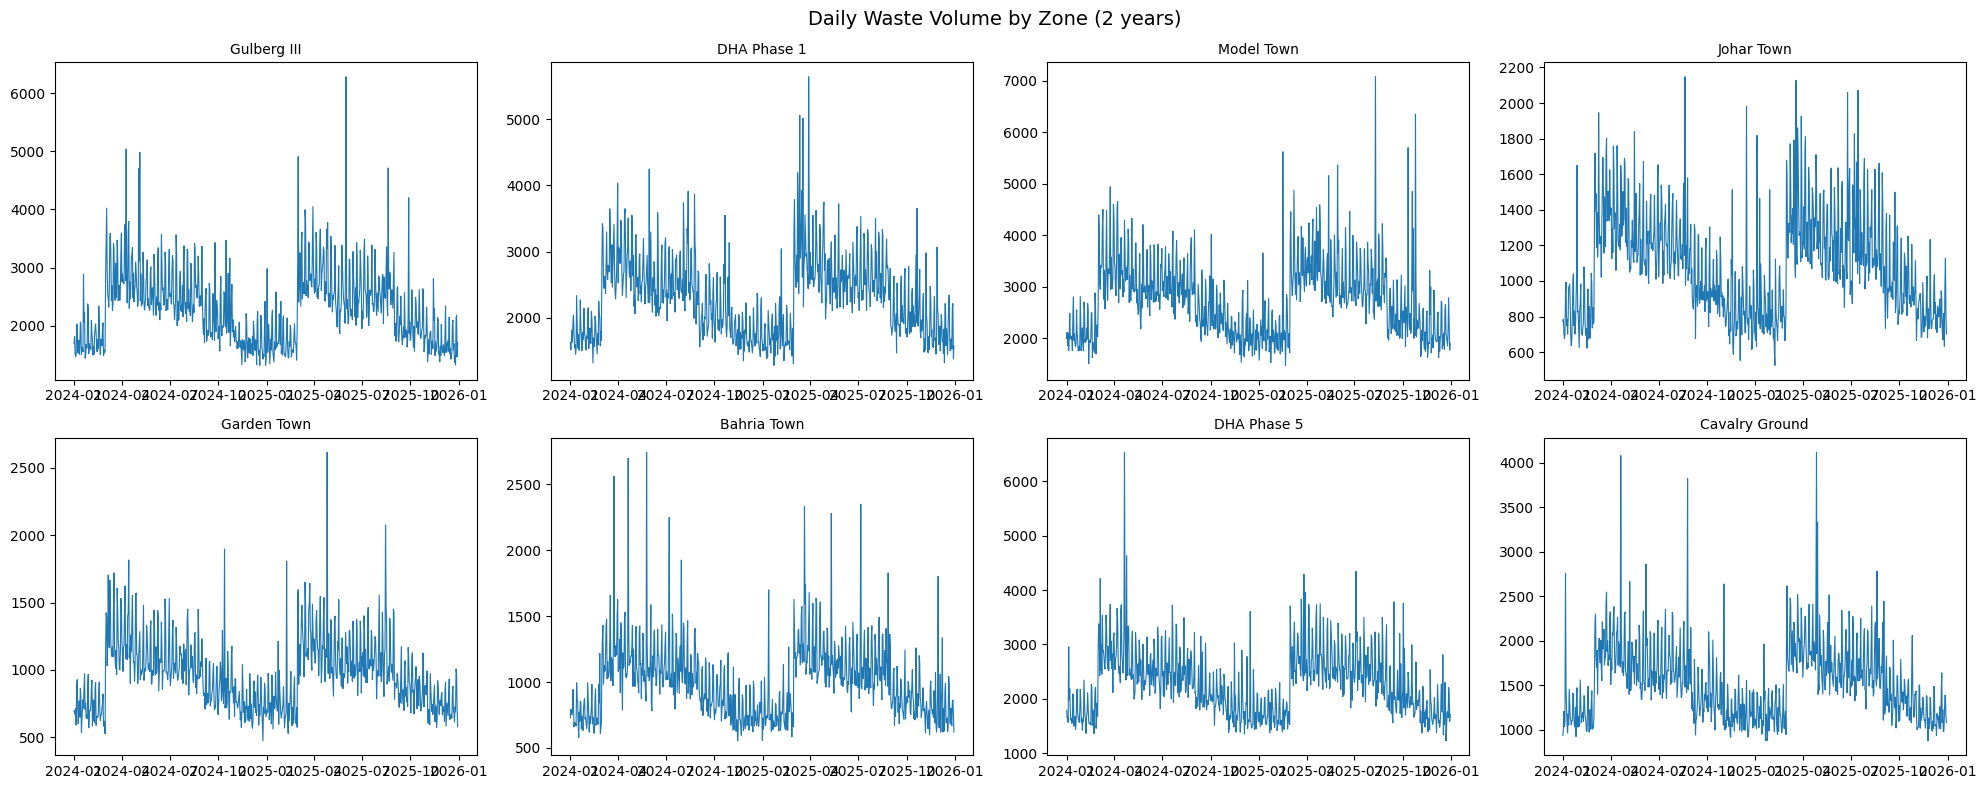

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

df = pd.read_csv(r"C:\SWOS\module4_prediction\data\waste_history.csv")
df['date'] = pd.to_datetime(df['date'])

print(f"Total records: {len(df)}")
print(f"Date range: {df['date'].min()} → {df['date'].max()}")
print(f"Zones: {df['zone'].nunique()}")
print(f"Waste types: {df['waste_type'].unique()}")

# Daily total per zone
daily = df.groupby(['date','zone'])['volume_kg'].sum().reset_index()

# Plot
fig, axes = plt.subplots(2, 4, figsize=(20, 8))
axes = axes.flatten()
for i, zone in enumerate(df['zone'].unique()):
    zone_data = daily[daily['zone'] == zone]
    axes[i].plot(zone_data['date'], zone_data['volume_kg'], linewidth=0.8)
    axes[i].set_title(zone, fontsize=10)
    axes[i].set_xlabel('')
plt.suptitle('Daily Waste Volume by Zone (2 years)', fontsize=14)
plt.tight_layout()
plt.show()

In [10]:
from prophet import Prophet
import pickle
import os

MODELS_DIR = Path(r"C:\SWOS\module4_prediction\models")
MODELS_DIR.mkdir(exist_ok=True)

# Aggregate daily by zone
daily_total = df.groupby(['date','zone'])['volume_kg'].sum().reset_index()

models = {}
forecasts = {}

for zone in df['zone'].unique():
    print(f"Training Prophet for: {zone}...")
    
    zone_df = daily_total[daily_total['zone'] == zone][['date','volume_kg']].copy()
    zone_df.columns = ['ds', 'y']
    zone_df = zone_df.sort_values('ds')
    
    model = Prophet(
        yearly_seasonality  = True,
        weekly_seasonality  = True,
        daily_seasonality   = False,
        changepoint_prior_scale = 0.1,
        seasonality_prior_scale = 10,
    )
    
    # Add Ramadan seasonality
    model.add_seasonality(
        name='ramadan',
        period=354.37,
        fourier_order=5
    )
    
    model.fit(zone_df)
    models[zone] = model
    
    # Forecast next 90 days
    future = model.make_future_dataframe(periods=550)
    forecast  = model.predict(future)
    forecasts[zone] = forecast
    
    print(f"  ✅ Done — {len(zone_df)} training points")

# Save models
with open(MODELS_DIR / "prophet_models.pkl", "wb") as f:
    pickle.dump(models, f)

print(f"\n✅ All Prophet models saved to {MODELS_DIR}")

21:48:57 - cmdstanpy - INFO - Chain [1] start processing
21:48:57 - cmdstanpy - INFO - Chain [1] done processing


Training Prophet for: Gulberg III...


21:48:57 - cmdstanpy - INFO - Chain [1] start processing
21:48:57 - cmdstanpy - INFO - Chain [1] done processing


  ✅ Done — 730 training points
Training Prophet for: DHA Phase 1...


21:48:58 - cmdstanpy - INFO - Chain [1] start processing
21:48:58 - cmdstanpy - INFO - Chain [1] done processing


  ✅ Done — 730 training points
Training Prophet for: Model Town...


... (6 outputs left out)

21:48:59 - cmdstanpy - INFO - Chain [1] start processing


  ✅ Done — 730 training points
Training Prophet for: DHA Phase 5...


21:48:59 - cmdstanpy - INFO - Chain [1] done processing
21:48:59 - cmdstanpy - INFO - Chain [1] start processing
21:48:59 - cmdstanpy - INFO - Chain [1] done processing


  ✅ Done — 730 training points
Training Prophet for: Cavalry Ground...
  ✅ Done — 730 training points

✅ All Prophet models saved to C:\SWOS\module4_prediction\models


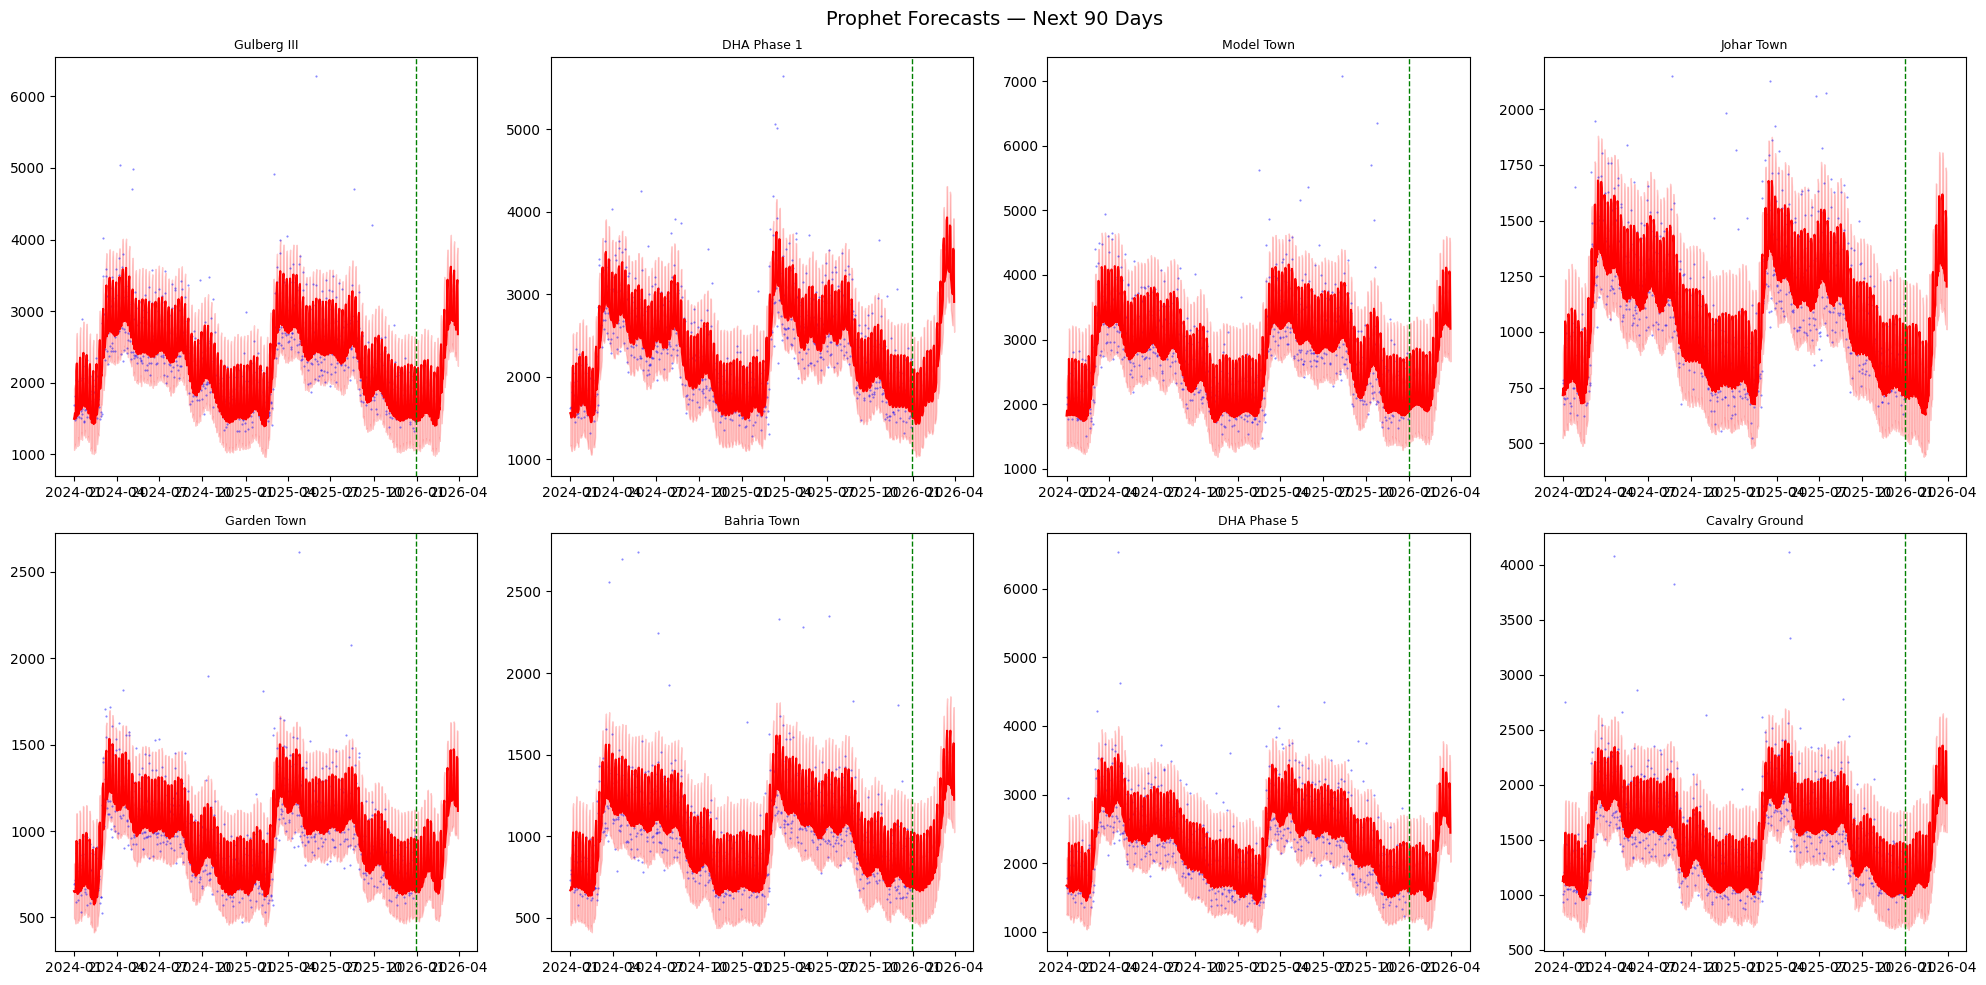

In [3]:
fig, axes = plt.subplots(2, 4, figsize=(20, 10))
axes = axes.flatten()

for i, zone in enumerate(list(forecasts.keys())[:8]):
    forecast = forecasts[zone]
    zone_df  = daily_total[daily_total['zone'] == zone]
    
    ax = axes[i]
    ax.plot(zone_df['date'], zone_df['volume_kg'],
            'b.', markersize=1, label='Actual', alpha=0.5)
    ax.plot(pd.to_datetime(forecast['ds']),
            forecast['yhat'], 'r-', linewidth=1.5, label='Forecast')
    ax.fill_between(
        pd.to_datetime(forecast['ds']),
        forecast['yhat_lower'],
        forecast['yhat_upper'],
        alpha=0.2, color='red'
    )
    ax.set_title(zone, fontsize=9)
    ax.axvline(pd.Timestamp('2025-12-31'), color='green',
               linestyle='--', linewidth=1, label='Forecast start')

plt.suptitle('Prophet Forecasts — Next 90 Days', fontsize=14)
plt.tight_layout()
plt.show()

In [8]:
from datetime import datetime, timedelta

today     = pd.Timestamp.today()
next_7    = today + pd.Timedelta(days=7)

print("=" * 55)
print("WASTE VOLUME FORECAST — NEXT 7 DAYS")
print("=" * 55)

weekly_forecast = {}

for zone, forecast in forecasts.items():
    forecast['ds'] = pd.to_datetime(forecast['ds'])
    today    = pd.Timestamp.today().normalize()
    next_7   = today + pd.Timedelta(days=7)

    future_mask = (forecast['ds'] >= today) & (forecast['ds'] <= next_7)
    week_data   = forecast[future_mask]

    if len(week_data) == 0:
        print(f"\n{zone} — no forecast data for next 7 days, using last 7")
        week_data = forecast.tail(7)

    avg_daily = week_data['yhat'].mean()
    total     = week_data['yhat'].sum()
    peak_idx  = week_data['yhat'].idxmax()
    peak_day  = week_data.loc[peak_idx, 'ds']

    print(f"\n{zone}")
    print(f"  Avg daily:   {avg_daily:,.0f} kg")
    print(f"  7-day total: {total:,.0f} kg")
    print(f"  Peak day:    {str(peak_day)[:10]}")

print("\n✅ Forecast complete")

WASTE VOLUME FORECAST — NEXT 7 DAYS

Gulberg III — no forecast data for next 7 days, using last 7

Gulberg III
  Avg daily:   2,950 kg
  7-day total: 20,653 kg
  Peak day:    2026-03-29

DHA Phase 1 — no forecast data for next 7 days, using last 7

DHA Phase 1
  Avg daily:   3,176 kg
  7-day total: 22,229 kg
  Peak day:    2026-03-28

Model Town — no forecast data for next 7 days, using last 7

Model Town
  Avg daily:   3,454 kg
  7-day total: 24,179 kg
  Peak day:    2026-03-28

Johar Town — no forecast data for next 7 days, using last 7

Johar Town
  Avg daily:   1,330 kg
  7-day total: 9,310 kg
  Peak day:    2026-03-28

Garden Town — no forecast data for next 7 days, using last 7

Garden Town
  Avg daily:   1,221 kg
  7-day total: 8,549 kg
  Peak day:    2026-03-28

Bahria Town — no forecast data for next 7 days, using last 7

Bahria Town
  Avg daily:   1,347 kg
  7-day total: 9,431 kg
  Peak day:    2026-03-29

DHA Phase 5 — no forecast data for next 7 days, using last 7

DHA Phas

In [11]:
all_forecasts = []

for zone, forecast in forecasts.items():
    forecast['ds'] = pd.to_datetime(forecast['ds'])
    # Take last 90 rows as future forecast
    future_only = forecast.tail(90)[['ds', 'yhat', 'yhat_lower', 'yhat_upper']].copy()
    future_only['zone'] = zone
    all_forecasts.append(future_only)

forecast_df = pd.concat(all_forecasts)
forecast_df.columns = ['date', 'predicted_kg', 'lower_bound', 'upper_bound', 'zone']
forecast_df.to_csv(
    r"C:\SWOS\module4_prediction\data\forecasts.csv",
    index=False
)
print(f"✅ Forecasts saved — {len(forecast_df)} rows")
print(forecast_df.head(10))

✅ Forecasts saved — 720 rows
           date  predicted_kg  lower_bound  upper_bound         zone
1190 2027-04-05   2491.793380  2056.203332  2892.123774  Gulberg III
1191 2027-04-06   2513.993958  2099.501181  2926.386909  Gulberg III
1192 2027-04-07   2557.435755  2124.638877  2963.027149  Gulberg III
1193 2027-04-08   2476.381403  2066.836167  2886.154185  Gulberg III
1194 2027-04-09   2550.912289  2130.586014  2952.534387  Gulberg III
1195 2027-04-10   3133.866993  2691.524046  3558.353948  Gulberg III
1196 2027-04-11   3233.508075  2789.092990  3648.449047  Gulberg III
1197 2027-04-12   2496.445729  2073.684765  2913.520471  Gulberg III
1198 2027-04-13   2527.331965  2122.404474  2959.708571  Gulberg III
1199 2027-04-14   2577.113767  2165.072937  3004.617928  Gulberg III
